<a href="https://colab.research.google.com/github/martinkim1/KANT/blob/main/26/11/11_20_TIL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**다중 선형 회귀 (Multiple Linear Regression)**

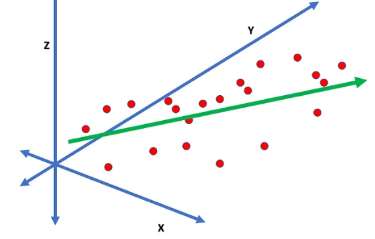

아이리스(Iris) 데이터셋의 첫 세 가지 변수, <br> 꽃받침의 길이(sepal length),
꽃받침의 너비(sepal width), 그리고 꽃잎의 길이(petal length)를 사용 <br>
**꽃잎의 너비(petal width)를 예측**하는 다중 선형 회귀 모델 개발

In [1]:
from sklearn import datasets
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

In [2]:
# Load the iris dataset
iris = datasets.load_iris()
X = iris.data[:, :3]  # 3개의 변수 선택 (sepal length, sepal width, petal length)
        # 모든 행 + 0, 1, 2번 열 선택
y = iris.data[:, 3]   # target  petal width
        # 모든 행 + 3번 열(petal width)만 선택

# 배열 슬라이싱(Array Slicing)
# 배열에서 원하는 범위의 요소만 잘라내는 기능
# NumPy 배열에서의 쉼표(,) : 차원(행, 열) 구분
# 기본 문법: 배열[시작:끝:간격]
  # 시작 인덱스는 포함되고, 끝 인덱스는 포함되지 않음 (시작 <= 인덱스 < 끝).
  # :만 쓰면 해당 차원의 전체 범위 의미
  # 시작 생략 -> 0번 인덱스부터  ex, :3   0~ 2번 인덱스까지

In [3]:
X

array([[5.1, 3.5, 1.4],
       [4.9, 3. , 1.4],
       [4.7, 3.2, 1.3],
       [4.6, 3.1, 1.5],
       [5. , 3.6, 1.4],
       [5.4, 3.9, 1.7],
       [4.6, 3.4, 1.4],
       [5. , 3.4, 1.5],
       [4.4, 2.9, 1.4],
       [4.9, 3.1, 1.5],
       [5.4, 3.7, 1.5],
       [4.8, 3.4, 1.6],
       [4.8, 3. , 1.4],
       [4.3, 3. , 1.1],
       [5.8, 4. , 1.2],
       [5.7, 4.4, 1.5],
       [5.4, 3.9, 1.3],
       [5.1, 3.5, 1.4],
       [5.7, 3.8, 1.7],
       [5.1, 3.8, 1.5],
       [5.4, 3.4, 1.7],
       [5.1, 3.7, 1.5],
       [4.6, 3.6, 1. ],
       [5.1, 3.3, 1.7],
       [4.8, 3.4, 1.9],
       [5. , 3. , 1.6],
       [5. , 3.4, 1.6],
       [5.2, 3.5, 1.5],
       [5.2, 3.4, 1.4],
       [4.7, 3.2, 1.6],
       [4.8, 3.1, 1.6],
       [5.4, 3.4, 1.5],
       [5.2, 4.1, 1.5],
       [5.5, 4.2, 1.4],
       [4.9, 3.1, 1.5],
       [5. , 3.2, 1.2],
       [5.5, 3.5, 1.3],
       [4.9, 3.6, 1.4],
       [4.4, 3. , 1.3],
       [5.1, 3.4, 1.5],
       [5. , 3.5, 1.3],
       [4.5, 2.3

In [4]:
y

array([0.2, 0.2, 0.2, 0.2, 0.2, 0.4, 0.3, 0.2, 0.2, 0.1, 0.2, 0.2, 0.1,
       0.1, 0.2, 0.4, 0.4, 0.3, 0.3, 0.3, 0.2, 0.4, 0.2, 0.5, 0.2, 0.2,
       0.4, 0.2, 0.2, 0.2, 0.2, 0.4, 0.1, 0.2, 0.2, 0.2, 0.2, 0.1, 0.2,
       0.2, 0.3, 0.3, 0.2, 0.6, 0.4, 0.3, 0.2, 0.2, 0.2, 0.2, 1.4, 1.5,
       1.5, 1.3, 1.5, 1.3, 1.6, 1. , 1.3, 1.4, 1. , 1.5, 1. , 1.4, 1.3,
       1.4, 1.5, 1. , 1.5, 1.1, 1.8, 1.3, 1.5, 1.2, 1.3, 1.4, 1.4, 1.7,
       1.5, 1. , 1.1, 1. , 1.2, 1.6, 1.5, 1.6, 1.5, 1.3, 1.3, 1.3, 1.2,
       1.4, 1.2, 1. , 1.3, 1.2, 1.3, 1.3, 1.1, 1.3, 2.5, 1.9, 2.1, 1.8,
       2.2, 2.1, 1.7, 1.8, 1.8, 2.5, 2. , 1.9, 2.1, 2. , 2.4, 2.3, 1.8,
       2.2, 2.3, 1.5, 2.3, 2. , 2. , 1.8, 2.1, 1.8, 1.8, 1.8, 2.1, 1.6,
       1.9, 2. , 2.2, 1.5, 1.4, 2.3, 2.4, 1.8, 1.8, 2.1, 2.4, 2.3, 1.9,
       2.3, 2.5, 2.3, 1.9, 2. , 2.3, 1.8])

In [5]:
# Split the data into training/testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [6]:
# linear regression object 생성
regr = LinearRegression()

# 모델 학습
regr.fit(X_train, y_train)

LinearRegression()

In [7]:
y_pred = regr.predict(X_test)

In [8]:
# The coefficients
print('Coefficients:', regr.coef_)

# The mean squared error
print('Mean squared error: %.2f' % mean_squared_error(y_test, y_pred))

# The coefficient of determination
print('Coefficient of determination: %.2f' % r2_score(y_test, y_pred))

# target  petal width
#        # sepal length, sepal width, petal length

Coefficients: [-0.19918374  0.20693216  0.52260085]
Mean squared error: 0.05
Coefficient of determination: 0.89


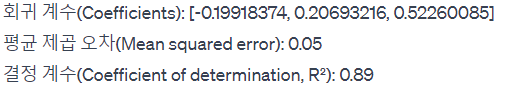

In [9]:
print("Intercept (절편):", regr.intercept_)

Intercept (절편): -0.22295759539281335


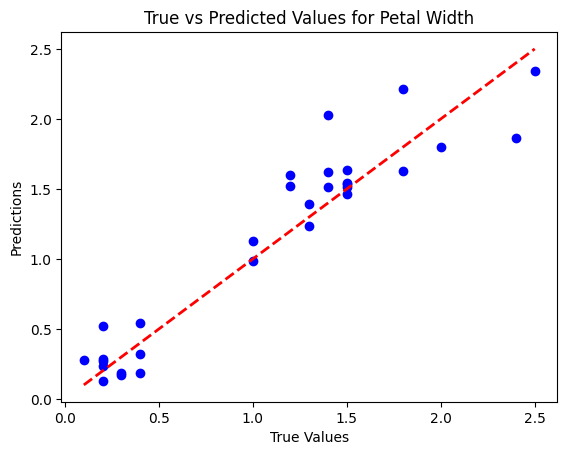

In [10]:
# 실제값 / 예측값 산점도(Actual vs. Predicted Scatter Plot)


plt.scatter(y_test, y_pred, color='blue')
plt.xlabel('True Values')
plt.ylabel('Predictions')
plt.title('True vs Predicted Values for Petal Width')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--', linewidth=2) # Diagonal line
plt.show()

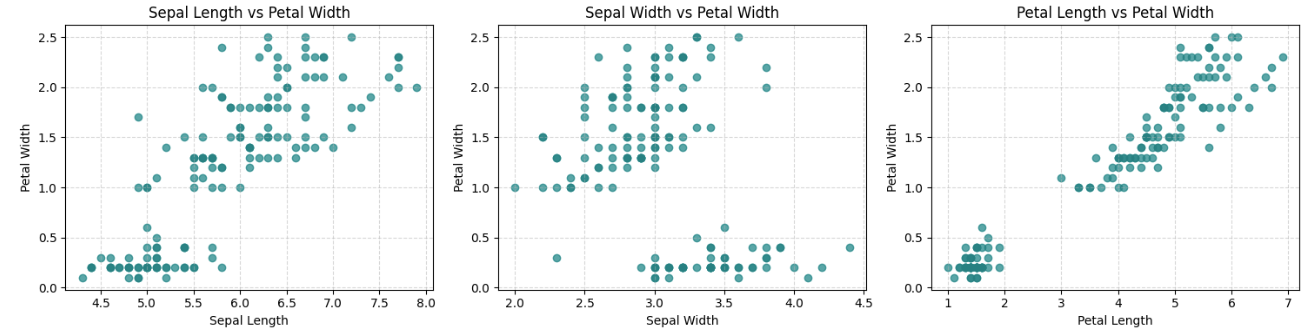